In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras import ops
from keras import Input
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense, SimpleRNN

import numpy as np

import pandas

keras.utils.set_random_seed(42)

In [ ]:
dataframe_raw = pandas.read_csv('ensino_unificado.csv', delimiter=';', usecols=["ANO","REGIAO","UF","CÓDIGO DO MUNICIPIO","REDE","CÓDIGO DA ESCOLA","Aprovação no 1º Ano do Ensino Fundamental"])



/tmp/ipykernel_4628/2470727406.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataframe_filtrado["REDE"] = dataframe_filtrado["REDE"].replace("Privada","Particular")


<Axes: >

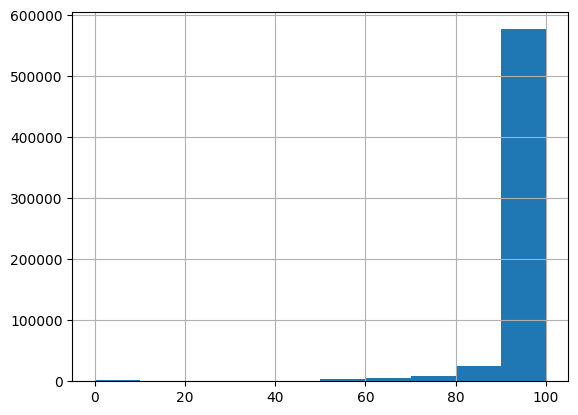

In [ ]:
import matplotlib.pyplot as plt

# Filtrando o dataframe para o período de interesse
dataframe_filtrado = dataframe_raw[(dataframe_raw["ANO"] >= 2014) & (dataframe_raw["ANO"] <= 2019)]

dataframe_filtrado["REDE"] = dataframe_filtrado["REDE"].replace("Privada","Particular")

#dataframe_filtrado = dataframe_filtrado[dataframe_filtrado["REDE"] == "Estadual"]
dataframe_filtrado["Aprovação no 1º Ano do Ensino Fundamental"].hist()




Análise dos dados

,ANO,mean,median,std
0,2014,96.991525,100.0,9.671758
1,2015,97.101648,100.0,9.562904
2,2016,97.160722,100.0,9.591214
3,2017,97.475840,100.0,8.819606
4,2018,97.607891,100.0,8.450502
5,2019,98.047225,100.0,7.656682


/tmp/ipykernel_4628/1455513259.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], x="ANO", y="Aprovação no 1º Ano do Ensino Fundamental", data=dataframe_filtrado, palette="Blues")


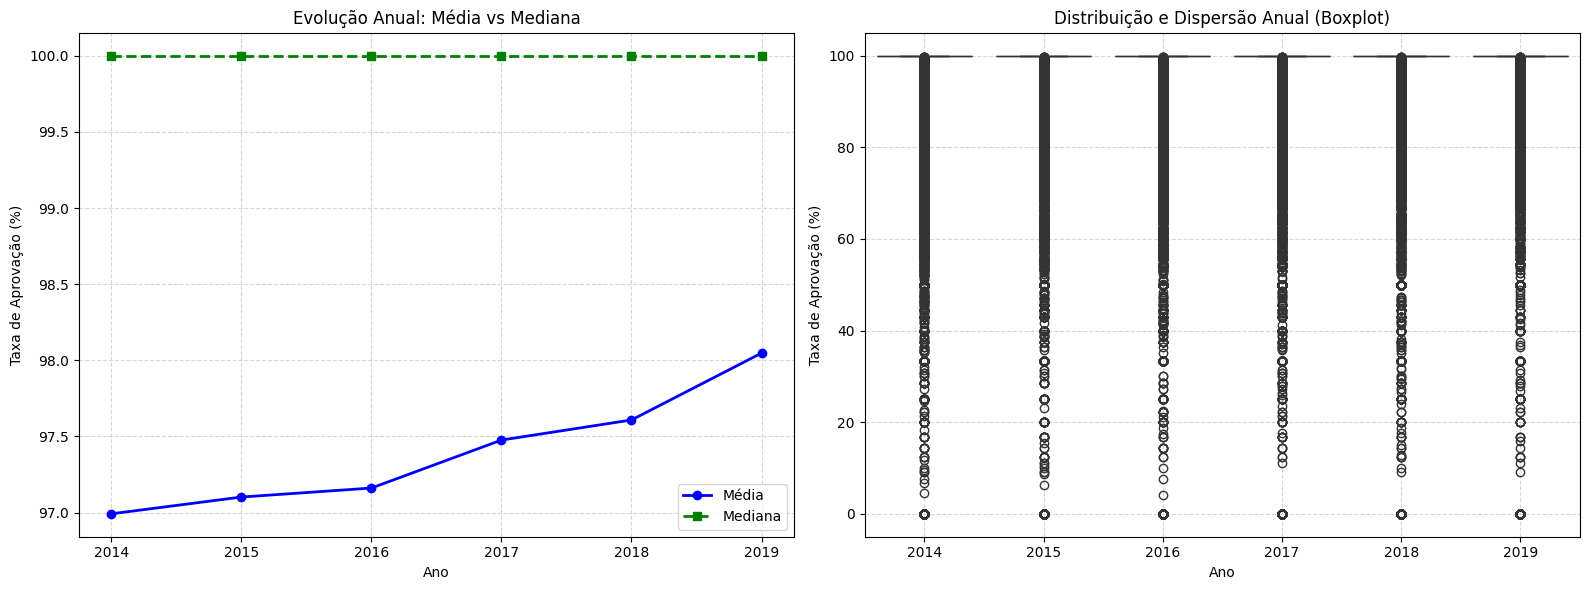

In [ ]:
# 1. Calculando métricas anuais robustas (Média e Mediana)
stats_anuais = dataframe_filtrado.groupby("ANO")["Aprovação no 1º Ano do Ensino Fundamental"].agg(["mean", "median", "std"]).reset_index()
display(stats_anuais)

# 2. Criando subplots para avaliar a variação anual de forma robusta
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Linha comparativa de Média vs Mediana
axes[0].plot(stats_anuais["ANO"], stats_anuais["mean"], marker='o', label='Média', color='blue', linewidth=2)
axes[0].plot(stats_anuais["ANO"], stats_anuais["median"], marker='s', label='Mediana', color='green', linewidth=2, linestyle='--')
axes[0].set_title("Evolução Anual: Média vs Mediana")
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Taxa de Aprovação (%)")
axes[0].set_xticks(stats_anuais["ANO"])
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Subplot 2: Boxplot para visualizar a distribuição e assimetria (skewness)
sns.boxplot(ax=axes[1], x="ANO", y="Aprovação no 1º Ano do Ensino Fundamental", data=dataframe_filtrado, palette="Blues")
axes[1].set_title("Distribuição e Dispersão Anual (Boxplot)")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Taxa de Aprovação (%)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

def aplicar_one_hot(dataframe, coluna):
    df = dataframe.copy()

    # Não permite transformar a última coluna, pois ela é o target
    if coluna == df.columns[-1]:
        raise ValueError("A última coluna é o target e não deve receber One-Hot Encoding.")

    # Posição original da coluna
    posicao = df.columns.get_loc(coluna)

    # Cria as novas colunas
    one_hot = pd.get_dummies(
        df[coluna],
        prefix=coluna,
        dtype=int
    )

    # Remove a coluna original
    df = df.drop(columns=[coluna])

    # Insere as novas colunas na mesma posição da original
    for i, nova_coluna in enumerate(one_hot.columns):
        df.insert(
            posicao + i,
            nova_coluna,
            one_hot[nova_coluna]
        )

    return df

In [ ]:
dataframe_normalizado = dataframe_filtrado.copy()

USAR_LOGIT=1

if USAR_LOGIT==1:
  epsilon = 1e-6
  dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"]/100
  dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = np.clip(dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"], epsilon, 1 - epsilon)
  dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = np.log(dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] / (1 - dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"]))
else:
  dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"]/100


dataframe_features =dataframe_normalizado.copy()
dataframe_features = aplicar_one_hot(dataframe_normalizado,"REGIAO")

colunas_pivot = list(dataframe_features.columns)
colunas_pivot.remove("ANO")
colunas_pivot.remove('Aprovação no 1º Ano do Ensino Fundamental')

print(colunas_pivot)
dataframe_pivotado = dataframe_features.pivot_table(
    values="Aprovação no 1º Ano do Ensino Fundamental",
    index=colunas_pivot,
    columns="ANO"
)

dataframe_pivotado.reset_index(inplace=True)
dataframe_pivotado.dropna(inplace=True)

dataframe_pivotado.rename(
    columns={
        "CÓDIGO DO MUNICIPIO":"codigo_municipio",
        "CÓDIGO DA ESCOLA":"codigo_escola",
        "REDE":"rede",
        "REGIAO":"regiao",
        "UF":"uf"
    },
    inplace=True
)


dataframe_pivotado.head()

['REGIAO_Centro-Oeste', 'REGIAO_Centro_Oeste', 'REGIAO_Nordeste', 'REGIAO_Norte', 'REGIAO_Sudeste', 'REGIAO_Sul', 'UF', 'CÓDIGO DO MUNICIPIO', 'REDE', 'CÓDIGO DA ESCOLA']


ANO,REGIAO_Centro-Oeste,REGIAO_Centro_Oeste,REGIAO_Nordeste,REGIAO_Norte,REGIAO_Sudeste,REGIAO_Sul,uf,codigo_municipio,rede,codigo_escola,2014,2015,2016,2017,2018,2019
2,0,0,0,0,0,1,PR,4100103,Municipal,41042590,3.055049,3.078568,1.918759,2.442347,1.90983,2.769406
5,0,0,0,0,0,1,PR,4100202,Municipal,41120027,1.469622,1.874690,2.483824,13.815510,13.81551,13.815510
7,0,0,0,0,0,1,PR,4100202,Municipal,41120140,13.815510,13.815510,13.815510,13.815510,13.81551,13.815510
9,0,0,0,0,0,1,PR,4100202,Municipal,41120230,3.547151,3.623315,13.815510,13.815510,13.81551,13.815510
12,0,0,0,0,0,1,PR,4100301,Municipal,41141342,3.944133,4.184591,13.815510,2.903111,3.89182,4.057396


#Prepara dataset features

In [ ]:
anos_entrada = [2014, 2015, 2016, 2017, 2018]
target = 2019

# Colunas geradas pelo one-hot
colunas_categoricas = [
    coluna for coluna in dataframe_pivotado.columns
    if coluna not in anos_entrada + [target]
]

colunas_categoricas.remove("codigo_municipio")
colunas_categoricas.remove("codigo_escola")
#colunas_categoricas.remove("regiao")
colunas_categoricas.remove("rede")
colunas_categoricas.remove("uf")

# Série temporal
X_temporal = dataframe_pivotado[anos_entrada].to_numpy(dtype="float32")

# (N, 5) -> (N, 5, 1)
X_temporal = np.expand_dims(X_temporal, axis=-1)

# Features categóricas
X_categorico = dataframe_pivotado[
    colunas_categoricas
].to_numpy(dtype="float32")

# Repete as características categóricas nos 5 timesteps
X_categorico = np.repeat(
    X_categorico[:, np.newaxis, :],
    repeats=5,
    axis=1
)

# Junta tudo
X = np.concatenate(
    [X_temporal, X_categorico],
    axis=2
)

y = dataframe_pivotado[
    [target]
].to_numpy(dtype="float32")

print("X:", X.shape)
print("y:", y.shape)

X: (74169, 5, 7)
y: (74169, 1)


In [ ]:


dataset_train, dataset_test = keras.utils.split_dataset(
    (X, y),
    left_size=0.7,
    shuffle=True,
    seed=42
)

dataset_train = dataset_train.batch(24)
dataset_test = dataset_test.batch(24)


#Roda Modelo

In [ ]:
numero_features = X.shape[2]

model = keras.Sequential([
    keras.Input(shape=(5, numero_features)),
    keras.layers.SimpleRNN(units=16,return_sequences=True),
    keras.layers.Dense(units=1,activation="linear")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.MeanAbsoluteError()]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 5, 16)          │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5, 1)           │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401 (1.57 KB)

 Trainable params: 401 (1.57 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    dataset_train,
    validation_data=dataset_test,
    epochs=4
)

Epoch 1/4
2164/2164 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 29.5012 - mean_absolute_error: 4.2582 - val_loss: 16.7286 - val_mean_absolute_error: 2.8675
Epoch 2/4
2164/2164 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 16.6095 - mean_absolute_error: 2.8636 - val_loss: 16.3863 - val_mean_absolute_error: 2.8064
Epoch 3/4
2164/2164 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 16.3415 - mean_absolute_error: 2.8310 - val_loss: 16.2012 - val_mean_absolute_error: 2.7802
Epoch 4/4
2164/2164 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 16.2767 - mean_absolute_error: 2.8251 - val_loss: 16.1802 - val_mean_absolute_error: 2.7766


#VALIDACAO MÉTODO POR 100

In [ ]:
X_train_validacao = np.concatenate([
    x.numpy() for x, y in dataset_train
], axis=0)

y_train_validacao = np.concatenate([
    y.numpy() for x, y in dataset_train
], axis=0).reshape(-1)


X_test_validacao = np.concatenate([
    x.numpy() for x, y in dataset_test
], axis=0)

y_test_validacao = np.concatenate([
    y.numpy() for x, y in dataset_test
], axis=0).reshape(-1)


# ----------------------------------------------------------
# Previsão da RNN JÁ TREINADA
# ----------------------------------------------------------

previsoes_rnn_completas = model.predict(
    X_test_validacao,
    verbose=0
)

# Seu modelo está com return_sequences=True.
# Portanto a saída tem formato:
#
# (amostras, 5 timesteps, 1 saída)
#
# Para prever 2019, usamos somente a saída do
# último timestep (após observar 2018).

#previsao_rnn = previsoes_rnn_completas.reshape(-1)
previsao_rnn = previsoes_rnn_completas[:, -1, 0]

# ----------------------------------------------------------
# Baselines
# ----------------------------------------------------------

# 1. Sempre prever a média de 2019 observada no TREINO
previsao_media = np.full(
    len(y_test_validacao),
    np.mean(y_train_validacao)
)


# 2. Sempre prever a mediana de 2019 observada no TREINO
previsao_mediana = np.full(
    len(y_test_validacao),
    np.median(y_train_validacao)
)


# 3. Persistência:
# "2019 será igual a 2018"
previsao_ultimo_ano = X_test_validacao[:, -1, 0]


# 4. Média dos 5 anos anteriores
# 2014, 2015, 2016, 2017 e 2018
previsao_media_5_anos = np.mean(
    X_test_validacao[:, :, 0],
    axis=1
)


# ----------------------------------------------------------
# Métricas
# ----------------------------------------------------------

def calcular_mae(real, previsto):
    return np.mean(np.abs(real - previsto))


def calcular_rmse(real, previsto):
    return np.sqrt(
        np.mean((real - previsto) ** 2)
    )


def calcular_r2(real, previsto):

    soma_residuos = np.sum(
        (real - previsto) ** 2
    )

    soma_total = np.sum(
        (real - np.mean(real)) ** 2
    )

    return 1 - (soma_residuos / soma_total)


# ----------------------------------------------------------
# Comparação
# ----------------------------------------------------------

modelos = {
    "RNN": previsao_rnn,
    "Média do treino": previsao_media,
    "Mediana do treino": previsao_mediana,
    "Último ano (2018)": previsao_ultimo_ano,
    "Média dos 5 anos": previsao_media_5_anos
}


resultados = []

for nome, previsao in modelos.items():

    resultados.append({

        "Modelo": nome,

        # Dados estão normalizados entre 0 e 1.
        # Multiplicando por 100, o erro volta
        # para pontos percentuais.
        "MAE (p.p.)": calcular_mae(
            y_test_validacao,
            previsao
        ) * 100,

        "RMSE (p.p.)": calcular_rmse(
            y_test_validacao,
            previsao
        ) * 100,

        "R²": calcular_r2(
            y_test_validacao,
            previsao
        )
    })


resultado_validacao = pd.DataFrame(resultados)

resultado_validacao = resultado_validacao.sort_values(
    "MAE (p.p.)"
).reset_index(drop=True)

display(
    resultado_validacao.round(4)
)


# ----------------------------------------------------------
# Quanto a RNN melhora em relação à persistência?
# ----------------------------------------------------------

mae_rnn = calcular_mae(
    y_test_validacao,
    previsao_rnn
)

mae_persistencia = calcular_mae(
    y_test_validacao,
    previsao_ultimo_ano
)

skill_rnn = 1 - (
    mae_rnn / mae_persistencia
)

print(
    f"Melhoria da RNN sobre o baseline "
    f"'2019 = 2018': {skill_rnn:.2%}"
)

,Modelo,MAE (p.p.),RMSE (p.p.),R²
0,Mediana do treino,209.799194,489.178314,-0.2254
1,Último ano (2018),229.001999,505.177887,-0.3069
2,RNN,248.016693,387.953094,0.2293
3,Média dos 5 anos,260.675690,420.623993,0.0940
4,Média do treino,338.272003,441.919800,-0.0001


Melhoria da RNN sobre o baseline '2019 = 2018': -8.30%


#VALIDACAO MÉTODO LOGIT

In [ ]:
# ==========================================================
# VALIDAÇÃO DO MODELO COM NORMALIZAÇÃO LOGIT
# Não retreina a rede.
# Utiliza model, dataset_train e dataset_test já existentes.
# ==========================================================

import numpy as np
import pandas as pd


# ----------------------------------------------------------
# Função inversa do Logit
# logit -> percentual [0, 100]
# ----------------------------------------------------------

def inversa_logit(valor):
    # Clip apenas para evitar overflow numérico no exp()
    valor = np.clip(valor, -50, 50)

    return 100 / (1 + np.exp(-valor))


# ----------------------------------------------------------
# Recupera os datasets NA ESCALA LOGIT
# ----------------------------------------------------------

X_train_logit = np.concatenate([
    x.numpy() for x, y in dataset_train
], axis=0)

y_train_logit = np.concatenate([
    y.numpy() for x, y in dataset_train
], axis=0).reshape(-1)


X_test_logit = np.concatenate([
    x.numpy() for x, y in dataset_test
], axis=0)

y_test_logit = np.concatenate([
    y.numpy() for x, y in dataset_test
], axis=0).reshape(-1)


# ----------------------------------------------------------
# Previsão
#
# IMPORTANTE:
# O modelo foi treinado em LOGIT, portanto recebe X em LOGIT.
# ----------------------------------------------------------

previsoes_logit = model.predict(
    X_test_logit,
    verbose=0
)


# return_sequences=True -> (amostras, timesteps, 1)
# Usamos somente a previsão do último timestep.
if previsoes_logit.ndim == 3:
    previsao_rnn_logit = previsoes_logit[:, -1, 0]
else:
    previsao_rnn_logit = previsoes_logit.reshape(-1)


# ----------------------------------------------------------
# RETORNO DA ESCALA LOGIT PARA 0-100
# ----------------------------------------------------------

y_train_percentual = inversa_logit(
    y_train_logit
)

y_test_percentual = inversa_logit(
    y_test_logit
)

X_test_percentual = inversa_logit(
    X_test_logit
)

previsao_rnn_percentual = inversa_logit(
    previsao_rnn_logit
)


# ----------------------------------------------------------
# Baselines
# Todos agora estão na mesma escala: 0-100
# ----------------------------------------------------------

# 1. Média do target no treino
previsao_media = np.full(
    len(y_test_percentual),
    np.mean(y_train_percentual)
)


# 2. Mediana do target no treino
previsao_mediana = np.full(
    len(y_test_percentual),
    np.median(y_train_percentual)
)


# 3. Persistência:
# previsão de 2019 = valor observado em 2018
previsao_ultimo_ano = X_test_percentual[:, -1, 0]


# 4. Média dos cinco anos anteriores
previsao_media_5_anos = np.mean(
    X_test_percentual[:, :, 0],
    axis=1
)


# ----------------------------------------------------------
# Métricas
# ----------------------------------------------------------

def calcular_mae(real, previsto):
    return np.mean(
        np.abs(real - previsto)
    )


def calcular_rmse(real, previsto):
    return np.sqrt(
        np.mean((real - previsto) ** 2)
    )


def calcular_r2(real, previsto):

    soma_residuos = np.sum(
        (real - previsto) ** 2
    )

    soma_total = np.sum(
        (real - np.mean(real)) ** 2
    )

    return 1 - (
        soma_residuos / soma_total
    )


# ----------------------------------------------------------
# Comparação
# ----------------------------------------------------------

modelos = {
    "RNN": previsao_rnn_percentual,
    "Média do treino": previsao_media,
    "Mediana do treino": previsao_mediana,
    "Último ano (2018)": previsao_ultimo_ano,
    "Média dos 5 anos": previsao_media_5_anos
}


resultados = []

for nome, previsao in modelos.items():

    resultados.append({

        "Modelo": nome,

        # Já estamos na escala 0-100.
        # NÃO multiplicar novamente por 100.
        "MAE (p.p.)": calcular_mae(
            y_test_percentual,
            previsao
        ),

        "RMSE (p.p.)": calcular_rmse(
            y_test_percentual,
            previsao
        ),

        "R²": calcular_r2(
            y_test_percentual,
            previsao
        )
    })


resultado_validacao = pd.DataFrame(resultados)

resultado_validacao = resultado_validacao.sort_values(
    "MAE (p.p.)"
).reset_index(drop=True)

display(
    resultado_validacao.round(4)
)


# ----------------------------------------------------------
# Skill da RNN em relação ao baseline 2019 = 2018
# ----------------------------------------------------------

mae_rnn = calcular_mae(
    y_test_percentual,
    previsao_rnn_percentual
)

mae_persistencia = calcular_mae(
    y_test_percentual,
    previsao_ultimo_ano
)

skill_rnn = 1 - (
    mae_rnn / mae_persistencia
)

print(
    f"Melhoria da RNN sobre o baseline "
    f"'2019 = 2018': {skill_rnn:.2%}"
)

,Modelo,MAE (p.p.),RMSE (p.p.),R²
0,RNN,1.6941,6.7287,-0.0284
1,Mediana do treino,1.7514,6.8625,-0.0697
2,Último ano (2018),2.5841,8.4748,-0.6313
3,Média dos 5 anos,2.6943,6.7584,-0.0375
4,Média do treino,2.9351,6.6356,-0.0001


Melhoria da RNN sobre o baseline '2019 = 2018': 34.44%
